In [1]:
import pandas as pd

In [3]:
df = pd.read_excel('../../03_data_raw/exploration_inputs/employment_year_table_completed.xlsx')
df2 = pd.read_excel('../../03_data_raw/exploration_inputs/employment_estimates_updated.xlsx')

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import re
# Load data
df = pd.read_excel('../../03_data_raw/exploration_inputs/employment_year_table_completed.xlsx')
df2 = pd.read_excel('../../03_data_raw/exploration_inputs/employment_estimates_updated.xlsx')
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()
def clean_number(v):
    if pd.isna(v):
        return None
    text = re.sub(r"[^0-9.,-]", "", str(v)).replace(",", "")
    try:
        return float(text)
    except ValueError:
        return None
# Build plant -> locations mapping from df2 text and df1 city names
city_lookup = {}
for city in df1["City"].dropna().unique():
    key = str(city).strip().lower()
    city_lookup.setdefault(key, set()).add(str(city).strip())
plant_to_locations = {}
for loc in df2["Location of affected units"].dropna().unique():
    loc_text = re.sub(r"\(.*?\)", "", str(loc))
    parts = [p.strip() for p in loc_text.split(",") if p.strip()]
    matched = set()
    for p in parts:
        p_low = p.lower()
        for city_key, cities in city_lookup.items():
            if p_low in city_key or city_key in p_low:
                matched.update(cities)
    for city in matched:
        plant_to_locations.setdefault(city, set()).add(loc)
plants = sorted(plant_to_locations)
print(f"Matched plants: {len(plants)}")
time_col = next((c for c in ["r_CreationTimestamp", "d_date_begin", "d_date_end"] if c in df2.columns), None)
if time_col is None:
    raise KeyError("No time column found in df2.")
cols = 2
rows = math.ceil(len(plants) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
for i, plant in enumerate(plants):
    ax = axes[i]
    locations = sorted(plant_to_locations[plant])
    # df2 time series
    ts = df2[df2["Location of affected units"].isin(locations)].copy()
    ts[time_col] = pd.to_datetime(ts[time_col], dayfirst=True, errors="coerce")
    ts["year"] = ts[time_col].dt.year
    ts["employees"] = ts["Number employe"].apply(clean_number)
    ts = ts.dropna(subset=["year", "employees"])
    ts_year = ts.groupby("year", as_index=False)["employees"].mean().sort_values("year")
    # df1 points
    pts = df1[df1["City "].astype(str).str.strip() == plant].copy()
    pts["employees"] = pts["employees"].apply(clean_number)
    pts = pts.dropna(subset=["year", "employees"]).sort_values("year")
    if not ts_year.empty:
        ax.plot(ts_year["year"], ts_year["employees"], marker="o", linewidth=2.2, label="df2 time series")
    if not pts.empty:
        ax.scatter(pts["year"], pts["employees"], color="red", s=60, zorder=5, label="df1 points")
    ax.set_title(str(plant).replace("_", " "), fontsize=11, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Employees")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(frameon=False)
for j in range(len(plants), len(axes)):
    fig.delaxes(axes[j])
fig.tight_layout()
plt.show()

KeyError: 'Location of affected units'

OSError: [Errno 30] Read-only file system: 'combined_employment_comparison_lines.png'

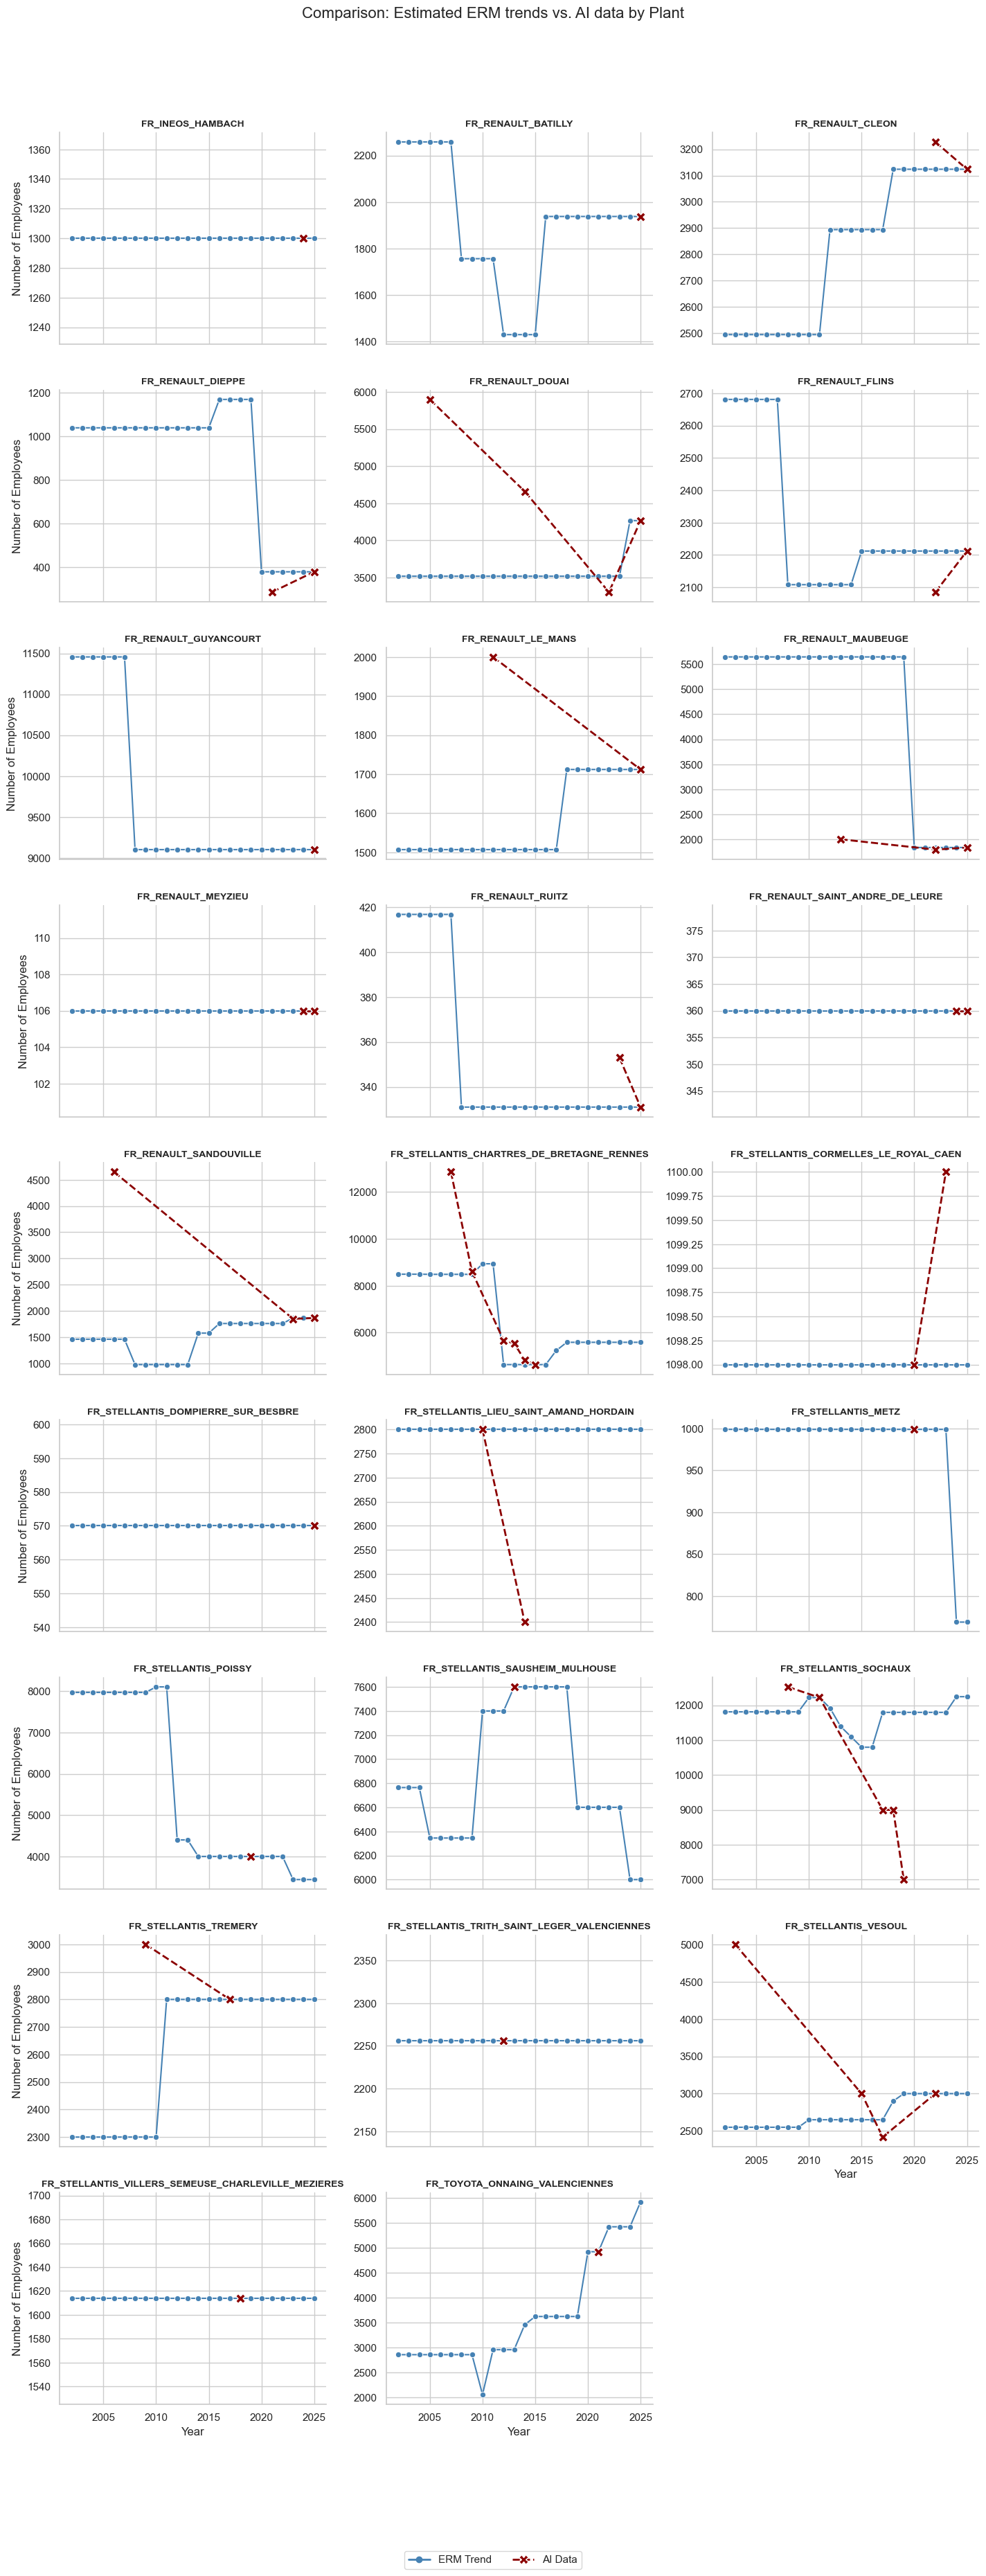

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Load the original dataset (Estimates/Lines)
df1 = pd.read_excel('../../03_data_raw/exploration_inputs/employment_estimates_updated.xlsx')
df1_plot = df1.dropna(subset=['year', 'employees']).copy()
df1_plot['year'] = df1_plot['year'].astype(int)
df1_plot = df1_plot.sort_values(by=['plant_id', 'year'])

# Load the newly uploaded dataset (Actuals/Points)
df2 = pd.read_excel('../../03_data_raw/exploration_inputs/employment_year_table_completed.xlsx')
df2_plot = df2.dropna(subset=['year', 'employees']).copy()
df2_plot['year'] = df2_plot['year'].astype(int)
# Sort by year to ensure lines connect chronologically left-to-right
df2_plot = df2_plot.sort_values(by=['plant_id', 'year'])

# Set the seaborn style
sns.set_theme(style="whitegrid")

# 1. Create subplots using Dataset 1 for the baseline line trends
g = sns.relplot(
    data=df1_plot, 
    x='year', 
    y='employees', 
    col='plant_id', 
    col_wrap=3,
    kind='line', 
    marker='o',
    color='steelblue',
    height=4, 
    aspect=1.2, 
    facet_kws={'sharey': False} # Allows each subplot to scale its own Y-axis
)

# 2. Overlay scatter points AND lines from Dataset 2 on the corresponding subplots
for ax, plant_id in zip(g.axes.flat, g.col_names):
    # Filter the new dataset for the current plant
    df2_sub = df2_plot[df2_plot['plant_id'] == plant_id]
    
    if not df2_sub.empty:
        # Plot the dashed line connecting the actual points
        ax.plot(
            df2_sub['year'], 
            df2_sub['employees'], 
            color='darkred', 
            linestyle='--',   # Dashed line for distinction
            linewidth=2,
            zorder=9          # Draws line just below the scatter points
        )
        
        # Plot the actual scatter points (markers)
        ax.scatter(
            df2_sub['year'], 
            df2_sub['employees'], 
            color='darkred', 
            s=100,            
            marker='X',       
            edgecolor='white',
            zorder=10,        # Ensure points are drawn on top
        )

# Customize subplot titles and axis labels
g.set_titles(col_template="{col_name}", size=10, weight='bold')
g.set_axis_labels("Year", "Number of Employees")

# Create a custom legend for the entire figure
custom_lines = [
    Line2D([0], [0], color='steelblue', marker='o', lw=2, label='ERM Trend'),
    Line2D([0], [0], color='darkred', linestyle='--', marker='X', markerfacecolor='darkred', markeredgecolor='white', markersize=10, lw=2, label='AI Data')
]
g.figure.legend(handles=custom_lines, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.0), frameon=True)

# Adjust layout to make room for the master title and bottom legend
plt.suptitle('Comparison: Estimated ERM trends vs. AI data by Plant', y=1.03, fontsize=16)
plt.tight_layout(rect=[0, 0.05, 1, 1]) 

# Save the plot
plt.savefig('combined_employment_comparison_lines.png')

In [ ]:
import random
number = random.randint(1, 100)
print('Random number:', number)